# Indian Railways Network & Traffic Analytics

**Author: Mansi Saxena**

**LinkedIn:** [Mansi Saxena](https://www.linkedin.com/in/mansi-saxena-049102362)  
**GitHub:** [050804mansi](https://github.com/050804mansi)  
**Email:** [mansi53245@gmail.com](mailto:mansi53245@gmail.com)

Analysis of official Indian Railways statistics: passenger journeys, freight output, network growth, state and zone infrastructure, and consequential train accidents. The observations are real published statistics from the Ministry of Railways Year Book 2023-24. The historical series is sparse, not annual. COVID-19 affected passenger operations in 2020-21.

Detailed citations and field definitions are in DATA_SOURCES.md.

## 1. Load and inspect source tables

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT = Path.cwd()
if not (PROJECT / "Data").exists():
    PROJECT = PROJECT.parent
DATA = PROJECT / "Data"

historical = pd.read_csv(DATA / "railway_historical_indicators.csv")
states = pd.read_csv(DATA / "state_rail_infrastructure_2023_24.csv")
zones = pd.read_csv(DATA / "zone_rail_infrastructure_2023_24.csv")
accidents = pd.read_csv(DATA / "consequential_train_accidents.csv")
print(historical.shape, states.shape, zones.shape, accidents.shape)
historical.head()


(11, 10) (31, 6) (17, 6) (5, 8)


,Financial_Year,Passengers_Originating_Million,Passenger_Kilometres_Million,Average_Passenger_Lead_Km,Revenue_Freight_Tonnes_Million,Revenue_Freight_NTKm_Million,Average_Freight_Lead_Km,Route_Km,Running_Track_Km,Total_Track_Km
0,1950-51,1284,66517,51.8,73.2,37565,513,53596,59315,77609
1,1960-61,1594,77665,48.7,119.8,72333,603,56247,63602,83706
2,1970-71,2431,118120,48.6,167.9,110696,659,59790,71669,98546
3,1980-81,3613,208558,57.7,195.9,147652,754,61240,75860,104480
4,1990-91,3858,295644,76.6,318.4,235785,741,62367,78607,108858


In [2]:
# Basic completeness, duplicate and reconciliation checks
for name, frame in {"historical": historical, "states": states, "zones": zones, "accidents": accidents}.items():
    print(name, "missing cells:", int(frame.isna().sum().sum()), "duplicate rows:", int(frame.duplicated().sum()))
print("State/UT route km sum:", states.Route_Km.sum())
print("All-India route km:", int(historical.iloc[-1].Route_Km))
states.loc[states.State_or_Union_Territory.eq("Goa")]


historical missing cells: 0 duplicate rows: 0
states missing cells: 0 duplicate rows: 0
zones missing cells: 0 duplicate rows: 0
accidents missing cells: 0 duplicate rows: 0
State/UT route km sum: 69181
All-India route km: 69181


,Region_Type,State_or_Union_Territory,Route_Km,Running_Track_Km,Total_Track_Km,Financial_Year
5,State,Goa,69,122,113,2023-24


## 2. Passenger demand and network length

Indexing measures to 100 in 1950-51 supports comparisons across different units. These are selected observations, not a continuous annual trend.

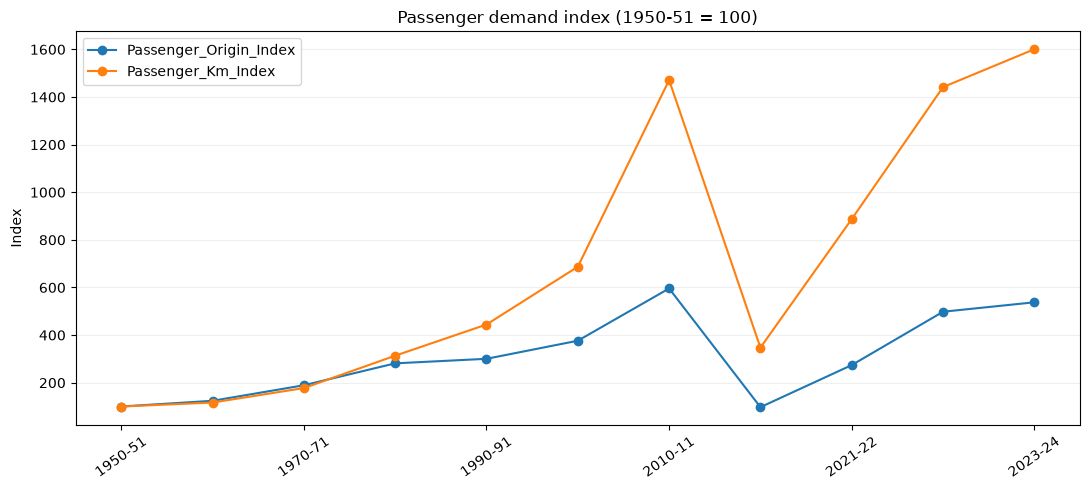

In [3]:
h = historical.copy()
h["Passenger_Origin_Index"] = h.Passengers_Originating_Million / h.Passengers_Originating_Million.iloc[0] * 100
h["Passenger_Km_Index"] = h.Passenger_Kilometres_Million / h.Passenger_Kilometres_Million.iloc[0] * 100
h.plot(x="Financial_Year", y=["Passenger_Origin_Index", "Passenger_Km_Index"], marker="o", figsize=(11,5), title="Passenger demand index (1950-51 = 100)")
plt.ylabel("Index"); plt.xlabel(""); plt.xticks(rotation=35); plt.grid(axis="y", alpha=.2); plt.tight_layout(); plt.show()


In [4]:
first, last = h.iloc[0], h.iloc[-1]
pd.DataFrame({
 "Measure": ["Passenger journeys", "Passenger-kilometres", "Route length"],
 "1950-51": [first.Passengers_Originating_Million, first.Passenger_Kilometres_Million, first.Route_Km],
 "2023-24": [last.Passengers_Originating_Million, last.Passenger_Kilometres_Million, last.Route_Km],
 "Change_multiple": [last.Passengers_Originating_Million/first.Passengers_Originating_Million,
                     last.Passenger_Kilometres_Million/first.Passenger_Kilometres_Million,
                     last.Route_Km/first.Route_Km]})


,Measure,1950-51,2023-24,Change_multiple
0,Passenger journeys,1284,6905,5.377726
1,Passenger-kilometres,66517,1064700,16.006434
2,Route length,53596,69181,1.290787


## 3. Revenue-earning freight output

The source notes that this freight series excludes Konkan Railway.

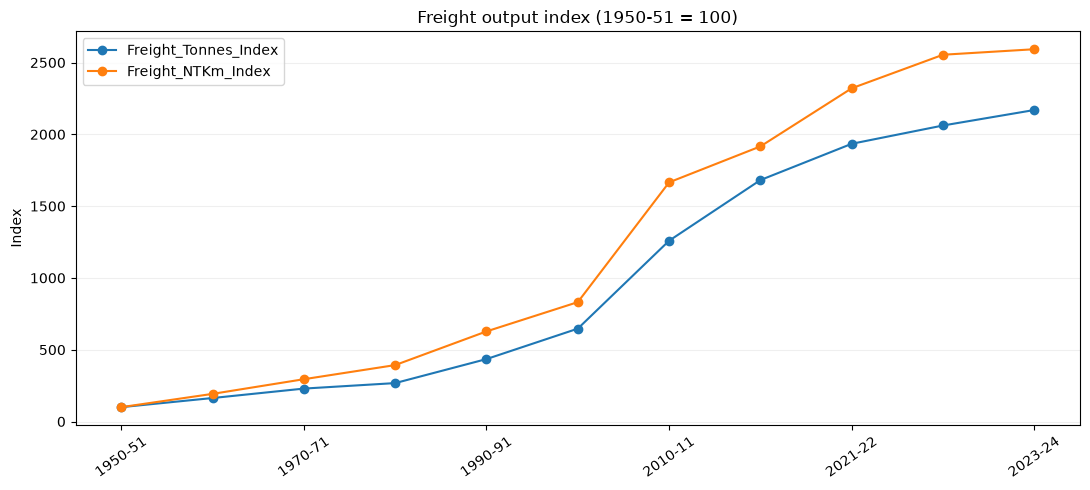

In [5]:
h["Freight_Tonnes_Index"] = h.Revenue_Freight_Tonnes_Million / h.Revenue_Freight_Tonnes_Million.iloc[0] * 100
h["Freight_NTKm_Index"] = h.Revenue_Freight_NTKm_Million / h.Revenue_Freight_NTKm_Million.iloc[0] * 100
h.plot(x="Financial_Year", y=["Freight_Tonnes_Index", "Freight_NTKm_Index"], marker="o", figsize=(11,5), title="Freight output index (1950-51 = 100)")
plt.ylabel("Index"); plt.xlabel(""); plt.xticks(rotation=35); plt.grid(axis="y", alpha=.2); plt.tight_layout(); plt.show()


## 4. State and zone infrastructure

State and zone figures are snapshots at the end of 2023-24. State and Union Territory rows remain identifiable in the data.

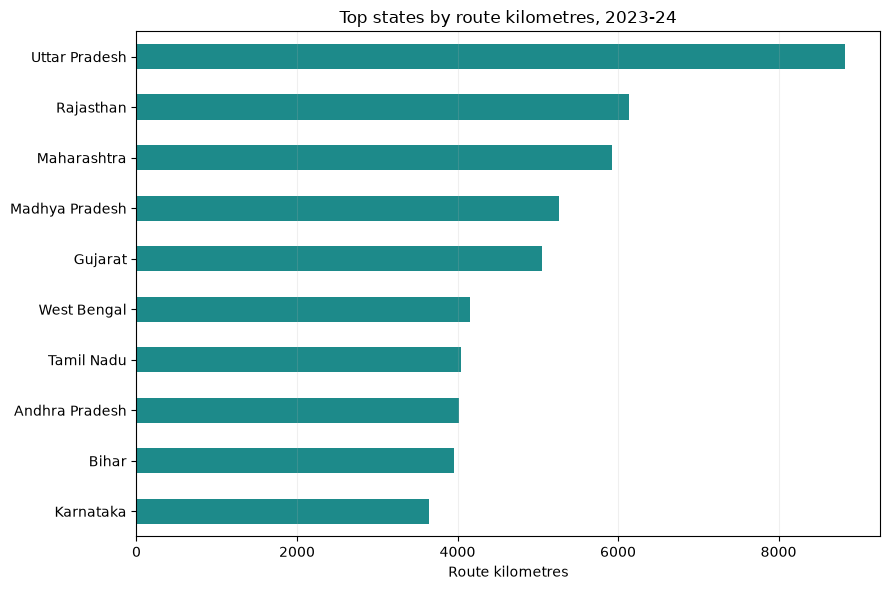

In [6]:
top_states = states.query("Region_Type == 'State'").nlargest(10, "Route_Km").sort_values("Route_Km")
top_states.plot.barh(x="State_or_Union_Territory", y="Route_Km", legend=False, color="#1d8a8a", figsize=(9,6), title="Top states by route kilometres, 2023-24")
plt.xlabel("Route kilometres"); plt.ylabel(""); plt.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()


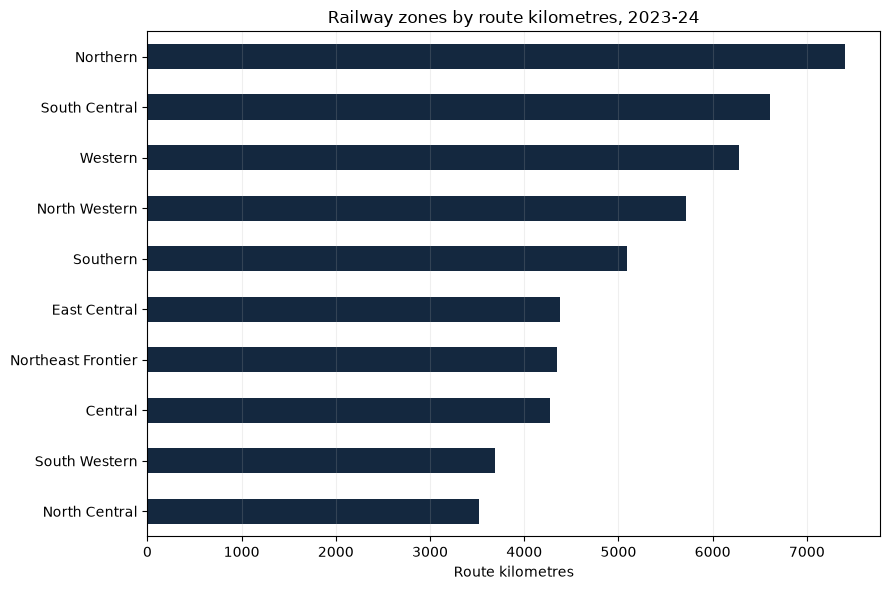

In [7]:
top_zones = zones.nlargest(10, "Route_Km").sort_values("Route_Km")
top_zones.plot.barh(x="Railway_Zone", y="Route_Km", legend=False, color="#14283f", figsize=(9,6), title="Railway zones by route kilometres, 2023-24")
plt.xlabel("Route kilometres"); plt.ylabel(""); plt.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()


## 5. Consequential train accidents

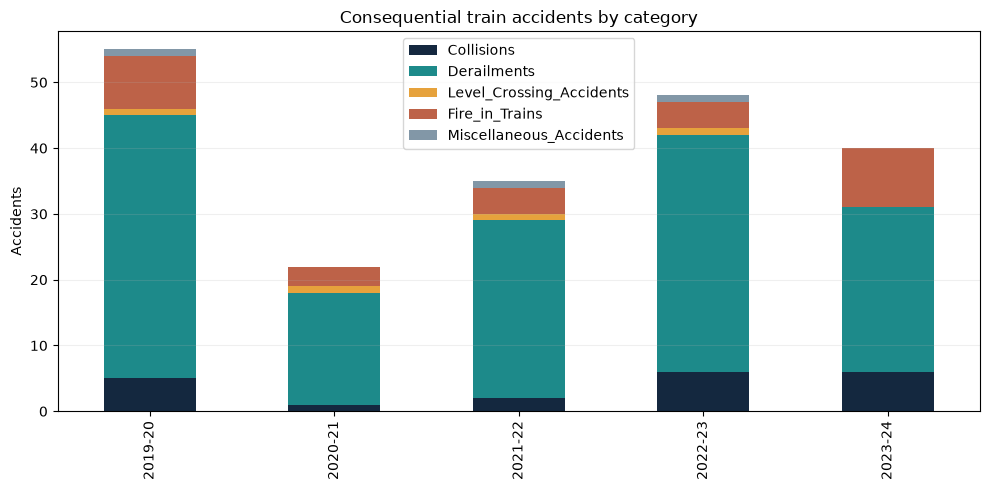

In [8]:
cause_columns = ["Collisions", "Derailments", "Level_Crossing_Accidents", "Fire_in_Trains", "Miscellaneous_Accidents"]
accidents.set_index("Financial_Year")[cause_columns].plot.bar(stacked=True, figsize=(10,5), color=["#14283f","#1d8a8a","#e6a23c","#bd6248","#8297a7"])
plt.title("Consequential train accidents by category"); plt.ylabel("Accidents"); plt.xlabel(""); plt.grid(axis="y",alpha=.2); plt.tight_layout(); plt.show()


## 6. Limitations and reproducible outputs

- Historical observations are selected years, not a complete annual panel.
- Passenger originating counts journeys, not unique people.
- COVID-19 affected the 2020-21 passenger figure.
- The source lists Goa with 122 running-track km and 113 total-track km. Both values are retained and flagged rather than silently changed.
- Trends and ratios are descriptive and do not establish causes.

Run python analysis.py from the project folder to recreate six charts and the PDF report. See DATA_SOURCES.md for attribution.

In [9]:
import sys
sys.path.insert(0, str(PROJECT))
from analysis import generate_charts, build_report
generate_charts()
build_report()
print("Charts and PDF report refreshed.")


Charts and PDF report refreshed.
